# Quantum Chess 5×5 — solution notebook
**Qiskit Fall Fest 2026 · Track 1: Quantum Games & Interactive Puzzles**

Gardner's 5×5 minichess where pieces can be in superposition. This notebook explains and demonstrates the quantum core:

1. **Squares are qubits**: |1⟩ = a piece is here, |0⟩ = empty.
2. **Split** (superposition): `√iSWAP` then `iSWAP` puts one piece on two squares, 50% each.
3. **Merge** (interference): the split run backwards returns the piece to one square with certainty.
4. **Entangling slide** (entanglement): a sliding piece moves only in the branches where the path is empty.
5. **Capture** (measurement): the board collapses and the capture succeeds or fizzles.

The same engine (`src/qchess`) powers the web app (`src/api.py` + `web/`), so everything below is exactly what runs in the game.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library import iSwapGate
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

from qchess import Game, parse as sq, name
from qchess.quantum import ISWAP, ISWAP_DG, SQRT_ISWAP, SQRT_ISWAP_DG, controlled_iswap

print("Qiskit", qiskit.__version__)

Qiskit 2.5.2


## 1. Split: one knight, two squares
The knight starts on **b1** (qubit in |1⟩). `√iSWAP(b1, a3)` moves half of its amplitude to a3; `iSWAP(b1, c3)` moves the rest to c3.

Starting from |100⟩ (b1 occupied): after `√iSWAP`, the state is (|b1⟩ + i|a3⟩)/√2; after `iSWAP`, it is i(|a3⟩ + |c3⟩)/√2.

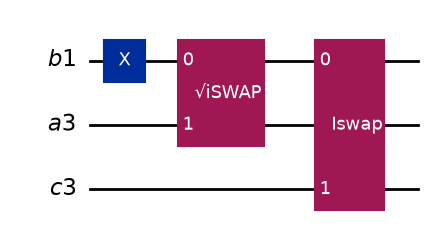

In [2]:
b1, a3, c3 = QuantumRegister(1, "b1"), QuantumRegister(1, "a3"), QuantumRegister(1, "c3")
split = QuantumCircuit(b1, a3, c3)
split.x(b1)                          # the knight is on b1
split.append(SQRT_ISWAP, [b1[0], a3[0]])   # half the amplitude to a3
split.append(ISWAP, [b1[0], c3[0]])        # the rest to c3
split.draw("mpl", style="iqp")

In [3]:
state = Statevector(split)
print("amplitudes:   ", {str(k): complex(np.round(v, 3)) for k, v in state.to_dict().items()})
print("probabilities:", {str(k): round(float(v), 3) for k, v in state.probabilities_dict().items()})
# bit strings read c3 a3 b1 (Qiskit is little-endian): '010' = knight on a3, '100' = knight on c3

amplitudes:    {'010': 0.707j, '100': 0.707j}
probabilities: {'010': 0.5, '100': 0.5}


Measuring the split knight 1000 times with Qiskit's `StatevectorSampler` primitive shows the 50/50 statistics a player experiences when they capture it:

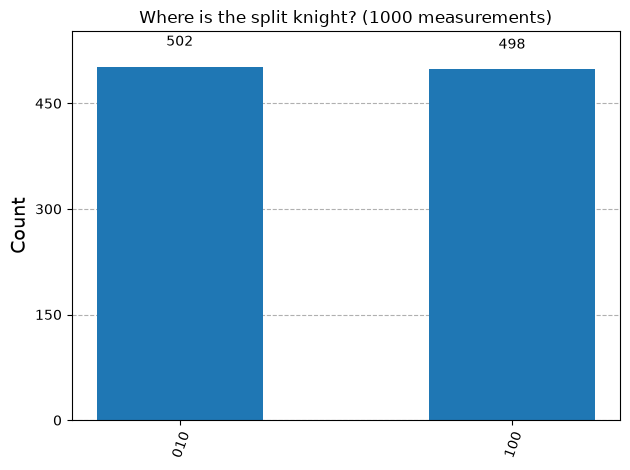

In [4]:
meas = split.copy()
meas.measure_all()
counts = StatevectorSampler(seed=7).run([meas], shots=1000).result()[0].data.meas.get_counts()
plot_histogram(counts, title="Where is the split knight? (1000 measurements)")

## 2. Merge: interference, not a coin flip
Running the split **backwards** (`iSWAP†`, then `√iSWAP†`) sends both halves back to b1 with **100%** certainty: the amplitudes add on b1 and cancel elsewhere.

A *classical* 50/50 piece (a coin flip, with no phase) cannot do this. The best a classical "merge" can do is keep the same 50/50 uncertainty about where it came from.

after quantum merge: {'001': 1.0}


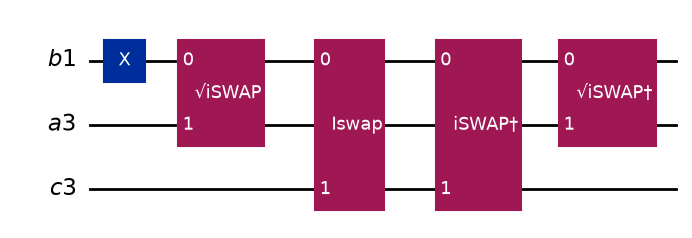

In [5]:
merge = split.copy()
merge.append(ISWAP_DG, [b1[0], c3[0]])
merge.append(SQRT_ISWAP_DG, [b1[0], a3[0]])
print("after quantum merge:", {str(k): round(float(v), 3) for k, v in Statevector(merge).probabilities_dict().items()})
merge.draw("mpl", style="iqp")

classical 50/50 mixture after the same gates: {'001': 0.5, '010': 0.5}


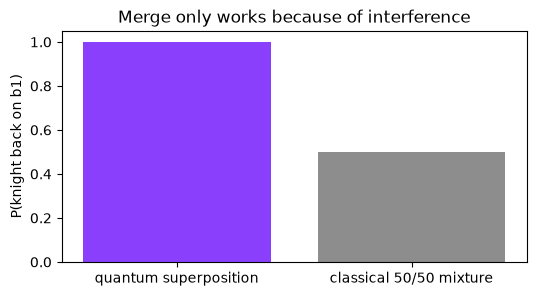

In [6]:
# A classical mixture (the knight is on a3 OR c3, each 50%) pushed through the same merge
mixture = {}
for start in ("a3", "c3"):
    qc = QuantumCircuit(b1, a3, c3)
    qc.x({"a3": a3, "c3": c3}[start])
    qc.append(ISWAP_DG, [b1[0], c3[0]])
    qc.append(SQRT_ISWAP_DG, [b1[0], a3[0]])
    for k, p in Statevector(qc).probabilities_dict().items():
        mixture[k] = mixture.get(k, 0) + 0.5 * p
print("classical 50/50 mixture after the same gates:", {str(k): round(float(v), 3) for k, v in mixture.items()})

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["quantum superposition", "classical 50/50 mixture"], [Statevector(merge).probabilities_dict().get("001", 0), mixture.get("001", 0)],
       color=["#8a3ffc", "#8d8d8d"])
ax.set_ylabel("P(knight back on b1)"); ax.set_ylim(0, 1.05); ax.set_title("Merge only works because of interference")
plt.show()

## 3. Entangling slide
A white rook on **a1** slides to **a4** while a black knight is on **a2** with 50% probability. The rook's iSWAP is **controlled on a2 being empty** (`ctrl_state=0`, drawn as an open circle). Afterwards rook and knight are entangled: *rook on a4 ⇔ knight not on a2*.

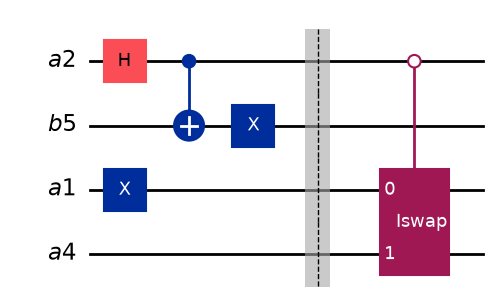

In [7]:
a1, a2, b5, a4 = (QuantumRegister(1, n) for n in ("a1", "a2", "b5", "a4"))
ent = QuantumCircuit(a2, b5, a1, a4)
ent.x(a1)                                           # rook on a1
ent.h(a2); ent.cx(a2, b5); ent.x(b5)                # prepare the knight: 50% on a2, 50% on b5
ent.barrier()
ent.append(controlled_iswap(1), [a2[0], a1[0], a4[0]])   # slide only if a2 is empty
ent.draw("mpl", style="iqp")

In [8]:
sv = Statevector(ent)
joint = sv.probabilities([0, 3])            # qubits a2 (bit 0) and a4 (bit 1)
for idx, label in enumerate(["no knight a2, no rook a4", "knight a2, no rook a4",
                             "no knight a2, rook a4", "knight a2, rook a4"]):
    print(f"{label:28s} {joint[idx]:.2f}")

no knight a2, no rook a4     0.00
knight a2, no rook a4        0.50
no knight a2, rook a4        0.50
knight a2, rook a4           0.00


The two "impossible" combinations have probability 0: measuring either piece instantly tells you where the other is.

## 4. Capture = measurement
In the engine, a capture of a "maybe" piece measures its square with `Statevector.measure()`. Here the rook captures on a2 in 20 independent games:

In [9]:
from qchess.board import Piece

def capture_trial(seed):
    g = Game(seed=seed)
    g.pieces = {sq("a1"): Piece("wR", "w", "R"), sq("e1"): Piece("wK", "w", "K"),
                sq("c3"): Piece("bN", "b", "N"), sq("e5"): Piece("bK", "b", "K")}
    g.turn = "b"
    g.split(sq("c3"), sq("a2"), sq("b5"))     # knight 50% a2, 50% b5
    g.move(sq("a1"), sq("a2"))                 # rook attacks a2
    return g.log[-1]["events"]

results = [capture_trial(s) for s in range(20)]
captured = sum("captured" in " ".join(r) for r in results)
print(f"knight captured in {captured}/20 games, escaped (was on b5) in {20 - captured}/20")
print("example:", results[0])

knight captured in 8/20 games, escaped (was on b5) in 12/20
example: ['measured a2: N present', 'captured bN on a2']


## 5. A full game through the engine
Uppercase = White, lowercase = Black; a percentage marks a piece in superposition.

5  r   | n   | b   | q   | k   
4  p   | p   | p   | p   | p   
3 N 50%|  .  |N 50%|  .  |  .  
2  P   | P   | P   | P   | P   
1  R   |  .  | B   | Q   | K   
   a     b     c     d     e 

events: ['measured a3: N absent', 'the target was not there; the pawn stays']
5  r   | n   | b   | q   | k   
4  p   | p   | p   | p   | p   
3   .  |  .  | N   |  .  |  .  
2  P   | P   | P   | P   | P   
1  R   |  .  | B   | Q   | K   
   a     b     c     d     e 



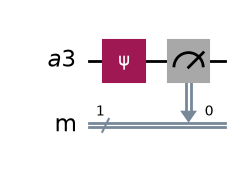

In [10]:
g = Game(seed=11)
g.split(sq("b1"), sq("a3"), sq("c3"))   # white knight -> a3 + c3
print(g.ascii(), "\n")
g.move(sq("b4"), sq("a3"))              # black pawn captures on a3: a measurement
print("events:", g.log[-1]["events"])
print(g.ascii(), "\n")
g.last_circuit.draw("mpl", style="iqp")

## 6. Classical vs quantum comparison
The **classical baseline** is the same engine with split and merge switched off (`Game(quantum=False)`), i.e. ordinary 5×5 minichess. We compare how many distinct actions each side has per turn over random games.

average actions per turn  classical: 13.5   quantum: 21.1


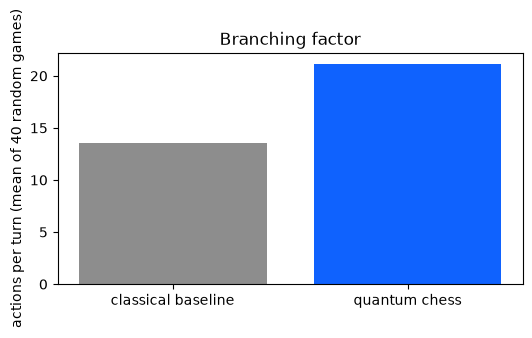

In [11]:
def random_game_branching(quantum, seed, plies=30):
    g, rng, counts = Game(seed=seed, quantum=quantum), np.random.default_rng(seed), []
    for _ in range(plies):
        if g.winner:
            break
        acts = []
        for s, p in list(g.pieces.items()):
            if p.color != g.turn:
                continue
            o = g.options(s)
            acts += [("move", s, t) for t in o["move"] + o["capture"]]
            n = len(o["split"])
            acts += [("split", s, o["split"][i], o["split"][j]) for i in range(n) for j in range(i + 1, n)]
            acts += [("merge", s, s2, t) for s2, ts in o["merge"].items() for t in ts]
        counts.append(len(acts))
        a = acts[rng.integers(len(acts))]
        {"move": lambda: g.move(a[1], a[2]), "split": lambda: g.split(a[1], a[2], a[3]),
         "merge": lambda: g.merge(a[1], a[2], a[3])}[a[0]]()
    return counts

classical = [np.mean(random_game_branching(False, s)) for s in range(40)]
quantum = [np.mean(random_game_branching(True, s)) for s in range(40)]
print(f"average actions per turn  classical: {np.mean(classical):.1f}   quantum: {np.mean(quantum):.1f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["classical baseline", "quantum chess"], [np.mean(classical), np.mean(quantum)], color=["#8d8d8d", "#0f62fe"])
ax.set_ylabel("actions per turn (mean of 40 random games)"); ax.set_title("Branching factor")
plt.show()

## 7. What real NISQ hardware would do
On a noisy device every gate has errors. Below, the split-then-merge circuit (which ideally returns the knight to b1 with probability 1) is run on Qiskit Aer with a depolarizing noise model of increasing strength.

CNOTs after transpiling split+merge: 8
error rate 0      P(back on b1) = 1.000
error rate 0.005  P(back on b1) = 0.847
error rate 0.01   P(back on b1) = 0.724
error rate 0.02   P(back on b1) = 0.531
error rate 0.05   P(back on b1) = 0.245
error rate 0.1    P(back on b1) = 0.144


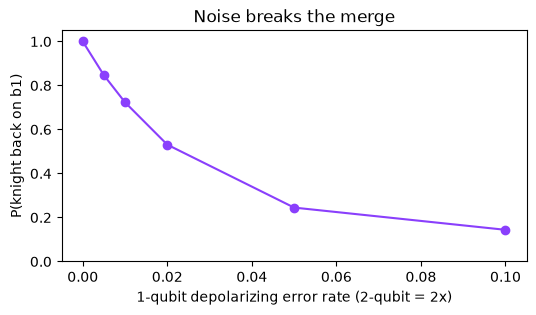

In [12]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

roundtrip = merge.copy()
roundtrip.measure_all()
rates, fidelity = [0, 0.005, 0.01, 0.02, 0.05, 0.1], []
for p in rates:
    noise = NoiseModel()
    if p:
        noise.add_all_qubit_quantum_error(depolarizing_error(p, 1), ["sx", "x", "rz"])
        noise.add_all_qubit_quantum_error(depolarizing_error(2 * p, 2), ["cx"])
    sim = AerSimulator(noise_model=noise, seed_simulator=1)
    tqc = transpile(roundtrip, basis_gates=["cx", "sx", "x", "rz"], optimization_level=1, seed_transpiler=1)
    counts = sim.run(tqc, shots=4000).result().get_counts()
    fidelity.append(counts.get("001", 0) / 4000)
print("CNOTs after transpiling split+merge:", tqc.count_ops().get("cx", 0))
for p, f in zip(rates, fidelity):
    print(f"error rate {p:<6} P(back on b1) = {f:.3f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(rates, fidelity, marker="o", color="#8a3ffc")
ax.set_xlabel("1-qubit depolarizing error rate (2-qubit = 2x)"); ax.set_ylabel("P(knight back on b1)")
ax.set_title("Noise breaks the merge"); ax.set_ylim(0, 1.05)
plt.show()

## 8. Takeaways and limitations
* Every quantum effect in the game is a Qiskit operation on a `Statevector`: no pseudo-random shortcut decides outcomes; measurement sampling is done by Qiskit.
* Only uncertain squares cost qubits; the engine caps the statevector at 16 qubits and forces a measurement beyond that, because exact simulation doubles in cost per qubit.
* On real hardware each iSWAP compiles to several CNOTs; as section 7 shows, even small error rates leak probability away from where the rules say a piece must be, and long games would outlast coherence times.
* Simplifications (no check, castling or en passant; classical pawns) keep the rules unambiguous in superposition.

**Run the game:** `uvicorn src.api:app` from the repository root, then open http://127.0.0.1:8000.